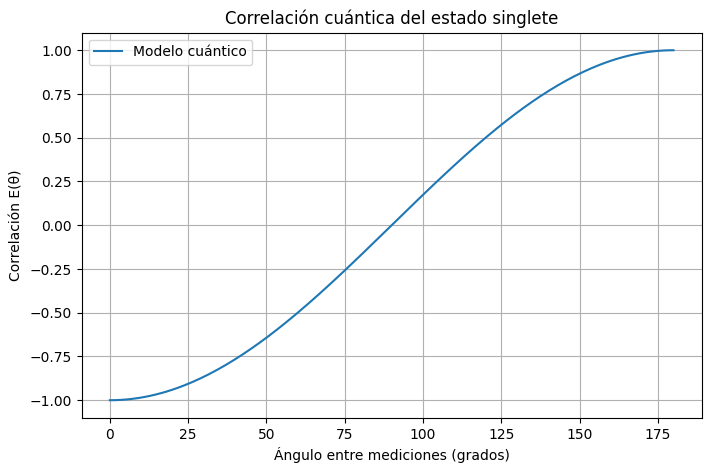

In [7]:

import numpy as np
import matplotlib.pyplot as plt

# Ángulos de medición entre 0° y 180°
theta = np.linspace(0, np.pi, 200)

# Correlación cuántica del estado singlete
E = -np.cos(theta)

plt.figure(figsize=(8, 5))
plt.plot(np.degrees(theta), E, label="Modelo cuántico")

plt.xlabel("Ángulo entre mediciones (grados)")
plt.ylabel("Correlación E(θ)")
plt.title("Correlación cuántica del estado singlete")
plt.grid(True)
plt.legend()
plt.show()


Correlación simulada: -1.0
Primeros 10 resultados de Alicia: [-1  1  1 -1 -1  1 -1  1 -1 -1]
Primeros 10 resultados de Bob:    [ 1 -1 -1  1  1 -1  1 -1  1  1]


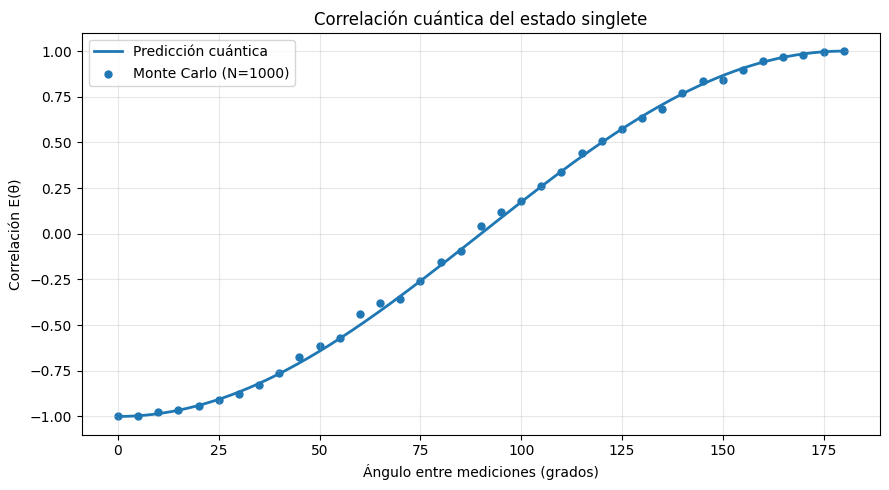

Correlación teórica: -0.7071

N =   100 | E = -0.7200 | Error absoluto = 0.0129
N =  1000 | E = -0.7280 | Error absoluto = 0.0209
N = 10000 | E = -0.7070 | Error absoluto = 0.0001


In [8]:

import numpy as np
import matplotlib.pyplot as plt

# Generador de números aleatorios reproducible
rng = np.random.default_rng(42)

# Número de pares de partículas por ángulo
N = 1000

def simular_correlacion(theta, N, rng):
    # Resultado de Alicia: +1 o -1
    A = rng.choice([-1, 1], size=N)

    # Probabilidad de que Bob obtenga
    # el resultado opuesto al de Alicia
    p_opuesto = (1 + np.cos(theta)) / 2

    # Decidir si los resultados son opuestos
    opuestos = rng.random(N) < p_opuesto

    # Construir los resultados de Bob
    B = np.where(opuestos, -A, A)

    # Correlación estimada
    E = np.mean(A * B)

    return E, A, B

theta = np.deg2rad(0)

E, A, B = simular_correlacion(theta, N, rng)

print("Correlación simulada:", E)
print("Primeros 10 resultados de Alicia:", A[:10])
print("Primeros 10 resultados de Bob:   ", B[:10])

angulos = np.linspace(0, 180, 37)
correlaciones = []

for angulo in angulos:
    theta = np.deg2rad(angulo)

    E, _, _ = simular_correlacion(theta, N, rng)
    correlaciones.append(E)

correlaciones = np.array(correlaciones)

# Curva cuántica teórica
angulos_teoria = np.linspace(0, 180, 500)
E_teoria = -np.cos(np.deg2rad(angulos_teoria))

plt.figure(figsize=(9, 5))

plt.plot(
    angulos_teoria,
    E_teoria,
    label="Predicción cuántica",
    linewidth=2
)

plt.scatter(
    angulos,
    correlaciones,
    label=f"Monte Carlo (N={N})",
    s=25
)

plt.xlabel("Ángulo entre mediciones (grados)")
plt.ylabel("Correlación E(θ)")
plt.title("Correlación cuántica del estado singlete")
plt.ylim(-1.1, 1.1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

theta = np.deg2rad(45)
E_teorica = -np.cos(theta)

print(f"Correlación teórica: {E_teorica:.4f}")
print()

for N_prueba in [100, 1000, 10000]:
    E, _, _ = simular_correlacion(
        theta, N_prueba, rng
    )

    error = abs(E - E_teorica)

    print(
        f"N = {N_prueba:5d} | "
        f"E = {E:.4f} | "
        f"Error absoluto = {error:.4f}"
    )


E(a,b)   = -0.7136
E(a,b')  = 0.7124
E(a',b)  = -0.7088
E(a',b') = -0.7158

S simulado = -2.8506
|S| = 2.8506
Límite clásico CHSH = 2
Máximo cuántico = 2.8284
N =    100  |S| = 3.1000
N =   1000  |S| = 2.8420
N =  10000  |S| = 2.8258
N = 100000  |S| = 2.8239

Valor teórico: 2.8284


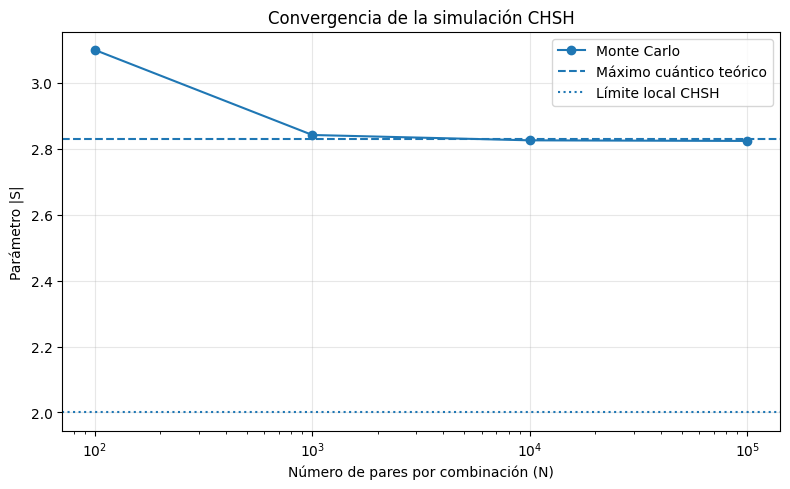

In [9]:
## 2. Simulación de la desigualdad CHSH
# Orientaciones de los aparatos, en grados
a = 0
a_prima = 90
b = 45
b_prima = 135

# Número de pares de partículas simulados por combinación
N_chsh = 10000

# Calculamos las cuatro correlaciones
E_ab, _, _ = simular_correlacion(
    np.radians(a - b), N_chsh, rng
)

E_ab_prima, _, _ = simular_correlacion(
    np.radians(a - b_prima), N_chsh, rng
)

E_a_prima_b, _, _ = simular_correlacion(
    np.radians(a_prima - b), N_chsh, rng
)

E_a_prima_b_prima, _, _ = simular_correlacion(
    np.radians(a_prima - b_prima), N_chsh, rng
)

# Parámetro CHSH
S = E_ab - E_ab_prima + E_a_prima_b + E_a_prima_b_prima

print(f"E(a,b)   = {E_ab:.4f}")
print(f"E(a,b')  = {E_ab_prima:.4f}")
print(f"E(a',b)  = {E_a_prima_b:.4f}")
print(f"E(a',b') = {E_a_prima_b_prima:.4f}")

print(f"\nS simulado = {S:.4f}")
print(f"|S| = {abs(S):.4f}")
print(f"Límite clásico CHSH = 2")
print(f"Máximo cuántico = {2*np.sqrt(2):.4f}")

# Diferentes cantidades de pares por combinación
valores_N = [100, 1000, 10000, 100000]

S_resultados = []

for N_actual in valores_N:

    E1, _, _ = simular_correlacion(np.radians(a - b), N_actual, rng)
    E2, _, _ = simular_correlacion(np.radians(a - b_prima), N_actual, rng)
    E3, _, _ = simular_correlacion(np.radians(a_prima - b), N_actual, rng)
    E4, _, _ = simular_correlacion(np.radians(a_prima - b_prima), N_actual, rng)

    S_actual = E1 - E2 + E3 + E4
    S_resultados.append(abs(S_actual))

    print(f"N = {N_actual:6d}  |S| = {abs(S_actual):.4f}")

print(f"\nValor teórico: {2*np.sqrt(2):.4f}")

plt.figure(figsize=(8, 5))

# Resultados obtenidos en la simulación
plt.plot(valores_N, S_resultados, 'o-',
         label='Monte Carlo')

# Predicción cuántica ideal
plt.axhline(2*np.sqrt(2), linestyle='--',
            label='Máximo cuántico teórico')

# Límite de variables ocultas locales
plt.axhline(2, linestyle=':',
            label='Límite local CHSH')

plt.xscale('log')

plt.xlabel('Número de pares por combinación (N)')
plt.ylabel('Parámetro |S|')
plt.title('Convergencia de la simulación CHSH')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig('convergencia_CHSH.png', dpi=300)
plt.show()